# Health Study
## Part 1: Statistical Analysis

### 1. Data Exploration

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Läser in datasetet och kontrollera dess struktur och innehåll

df = pd.read_csv("../data/health_study_dataset.csv")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

display(df.head())
display(df.dtypes.to_frame(name="Data type"))


Dataset shape: (800, 9)
Missing values: 0


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


,Data type
id,int64
age,int64
sex,str
height,float64
weight,float64
systolic_bp,float64
cholesterol,float64
smoker,str
disease,int64


### Data validation
The dataset contains 800 rows and 9 columns. No missing values were found, and the data types appear suitable for further analysis.

### 2. Descriptive Statistics

In [83]:
# Väljer vilka kolumner jag ska undersöka
columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]

# Använder agg för att beräkna flera statistiska mått samtidigt
stats = df[columns].agg(["mean", "median", "min", "max"]).T

# Avrundar resultatet till två decimaler och visar tabellen
stats = stats.round(2)
display(stats)


,mean,median,min,max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


### Results

The dataset contains 800 individuals. The mean age is 49.43 years, while the median age is 50 years. The youngest individual is 18 years old and the oldest is 90 years old.

The mean and median values are relatively close across the selected variables. All results have been rounded to two decimal places for better readability.

### 3. Data Visualization

#### 3.1 Blood Pressure Distribution

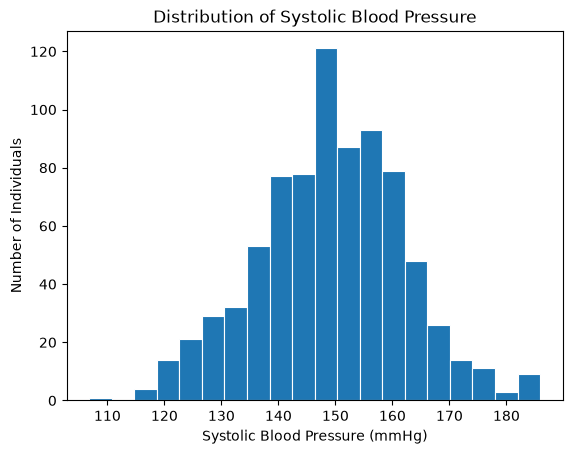

In [84]:
fig, ax = plt.subplots()

ax.hist(df["systolic_bp"], bins=20, edgecolor="white", linewidth=0.8)

ax.set_title("Distribution of Systolic Blood Pressure")
ax.set_xlabel("Systolic Blood Pressure (mmHg)")
ax.set_ylabel("Number of Individuals")

plt.show()

#### Results

Most systolic blood pressure values are concentrated between approximately 140 and 160 mmHg. The majority of values are found near the center of the distribution, with fewer observations at the lower and higher ends.

#### 3.2 Weight Distribution by Sex

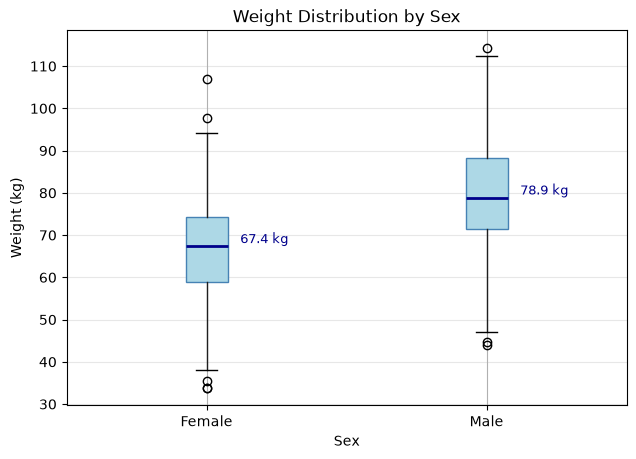

In [85]:
fig, ax = plt.subplots(figsize=(7, 5))

df.boxplot(
    column="weight",
    by="sex",
    ax=ax,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", edgecolor="steelblue"),
    medianprops=dict(color="darkblue", linewidth=2)
)

ax.set_title("Weight Distribution by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Weight (kg)")

# Ändrar F och M till tydligare namn
ax.set_xticklabels(["Female", "Male"])

# Gör stödlinjerna diskretare
ax.grid(axis="y", alpha=0.3)

fig.suptitle("")

# Beräknar medianvikten för respektive kön
medians = df.groupby("sex")["weight"].median()

# Placerar medianvärdena bredvid respektive låda
for i, median in enumerate(medians, start=1):
    ax.text(
        i + 0.12, median,
        f"{median:.1f} kg",
        fontsize=9,
        color="darkblue",
        va="bottom"
    )

plt.show()

In [86]:
# Undersöker viktstatistik för respektive kön
display(df.groupby("sex")["weight"].agg(["median", "min", "max"]).round(2))

# Kontrollerar observationen med ovanligt låg vikt
display(df.loc[df["weight"] == df["weight"].min()])

,median,min,max
sex,,,
F,67.4,33.7,106.9
M,78.9,44.1,114.4


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
709,710,75,F,149.6,33.7,159.1,5.0,Yes,0


### Results

The median weight is 67.4 kg for females and 78.9 kg for males, a difference of 11.5 kg.

The boxes represent the middle 50% of the values. For females, this range is approximately 59 to 74 kg, while for males it is approximately 71 to 88 kg.

The lines extending from the boxes show the range of values excluding outliers. Both groups have some outliers, represented by circles outside these lines.

The lowest recorded weight is 33.7 kg, which stands out in the boxplot. I examined this observation and found that the individual is 75 years old and 149.6 cm tall. Although the weight is unusually low, there is not enough information to determine whether it is an error.